In [ ]:
from google.colab import drive


drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import cv2


def load_images_from_folder(folder, size=(256, 256)):
    images = []
    for filename in os.listdir(folder):
        img = cv2.imread(os.path.join(folder, filename))
        if img is not None:
            img = cv2.resize(img, size)
            images.append(img)
    return np.array(images)



In [ ]:

train_images_folder = '/content/drive/MyDrive/ProjectTask1/train_data'
val_images_folder = '/content/drive/MyDrive/ProjectTask1/val_data/'

In [ ]:

train_images = load_images_from_folder(train_images_folder)
val_images = load_images_from_folder(val_images_folder)


In [ ]:
print("Train images shape:", train_images.shape)
print("Validation images shape:", val_images.shape)


Train images shape: (3000, 256, 256, 3)
Validation images shape: (600, 256, 256, 3)


In [ ]:

train_labels = np.loadtxt('/content/drive/MyDrive/ProjectTask1/train_labels.txt', dtype=int)
val_labels = np.loadtxt('/content/drive/MyDrive/ProjectTask1/val_labels.txt', dtype=int)


In [ ]:
print("Train labels shape:", train_labels.shape)
print("Validation labels shape:", val_labels.shape)

Train labels shape: (3000,)
Validation labels shape: (600,)


In [ ]:
from sklearn.decomposition import PCA

In [ ]:

train_images_flat = train_images.reshape(train_images.shape[0], -1)
val_images_flat = val_images.reshape(val_images.shape[0], -1)

In [ ]:

pca = PCA(n_components=100)
train_images_pca = pca.fit_transform(train_images_flat)
val_images_pca = pca.transform(val_images_flat)

In [ ]:

print("Train images after PCA shape:", train_images_pca.shape)
print("Validation images after PCA shape:", val_images_pca.shape)

Train images after PCA shape: (3000, 100)
Validation images after PCA shape: (600, 100)


In [ ]:
from tensorflow.keras import layers, models,regularizers
from tensorflow.keras.optimizers import Adam


In [ ]:

model = models.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),

    layers.Dense(61, activation='relu'),
    layers.Dropout(0.25),
    layers.BatchNormalization(),

    layers.Dense(61, activation='softmax')
])





In [ ]:

model.compile(optimizer=Adam(learning_rate=0.01),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:

history = model.fit(train_images_pca, train_labels,
                    epochs=25,
                    validation_data=(val_images_pca, val_labels),
                    batch_size=32)


Epoch 1/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.0626 - loss: 4.0907 - val_accuracy: 0.0350 - val_loss: 5.9673
Epoch 2/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1913 - loss: 3.2015 - val_accuracy: 0.0500 - val_loss: 5.4156
Epoch 3/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2332 - loss: 3.0349 - val_accuracy: 0.0550 - val_loss: 5.3939
Epoch 4/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2745 - loss: 2.8432 - val_accuracy: 0.0617 - val_loss: 5.5181
Epoch 5/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2777 - loss: 2.8222 - val_accuracy: 0.0767 - val_loss: 5.3988
Epoch 6/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2893 - loss: 2.7332 - val_accuracy: 0.0650 - val_loss: 5.3991
Epoch 7/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2989 - loss: 2.6309 - val_accuracy: 0.0667 - val_loss: 5.4841
Epoch 8/25
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3268 - loss: 2.5890 - val_accuracy: 0.0600 - val_loss:

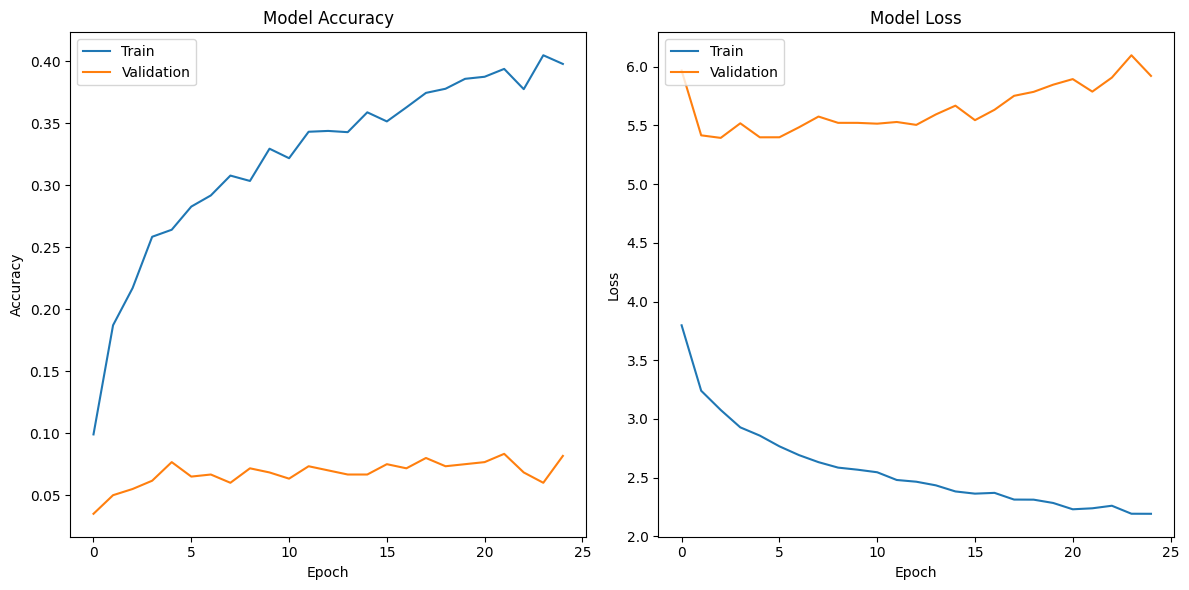

In [ ]:
import matplotlib.pyplot as plt

# Summarize history for accuracy
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Summarize history for loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()


#PATH TO ADD TEST _IMAGES PATH

In [ ]:
test_images_folder = '/content/drive/MyDrive/ProjectTask1/val_data/'
test_labels_path = '/content/drive/MyDrive/ProjectTask1/val_labels.txt'

# Load test data and labels
test_images_folder = '/content/drive/MyDrive/ProjectTask1/val_data'
test_labels = np.loadtxt('/content/drive/MyDrive/ProjectTask1/val_labels.txt', dtype=int)

# Load the test images
test_images = load_images_from_folder(test_images_folder)

# Flatten and transform the test images using the previously trained PCA
test_images_flat = test_images.reshape(test_images.shape[0], -1)
test_images_pca = pca.transform(test_images_flat)

# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_images_pca, test_labels, batch_size=32)

print(f"Test accuracy: {test_accuracy*100:.2f}%")
print(f"Test loss: {test_loss}")



19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0771 - loss: 5.9170 
Test accuracy: 8.17%
Test loss: 5.921641826629639
